In [1]:
%pip install -q diffusers

In [2]:
SID4 = 5330
SEED = SID4
print(f"SID4={SID4} SEED={SEED}")

SID4=5330 SEED=5330


# Assignment 9: Latent Diffusion on FashionMNIST

FashionMNIST images are resized to 128x128 and turned into 3 channels, so the VAE gives 4x16x16 latents.

In [3]:
import math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms as T
from torchvision.utils import make_grid
from diffusers import AutoencoderKL

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

tf = T.Compose([T.Resize(128), T.ToTensor(), T.Normalize([0.5], [0.5])])
train = datasets.FashionMNIST("../data", train=True, download=True, transform=tf)
test = datasets.FashionMNIST("../data", train=False, download=True, transform=tf)
CLASSES = train.classes
print(len(train), len(test))


def show(x, title, nrow=8):
    g = make_grid(x.cpu().clamp(-1, 1) * 0.5 + 0.5, nrow=nrow)
    plt.figure(figsize=(8, 8)); plt.imshow(g.permute(1, 2, 0)); plt.title(title); plt.axis("off"); plt.show()

device: cuda


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 207kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.83MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.0MB/s]

60000 10000


## 1. VAE Compression and Latent Representation

Pretrained `stabilityai/sd-vae-ft-mse`. Latents use the mean of the encoder distribution and are scaled by s = 0.18215.

In [4]:
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device).eval().requires_grad_(False)
S = 0.18215


@torch.no_grad()
def encode(x):
    return vae.encode(x.repeat(1, 3, 1, 1).to(device)).latent_dist.mean * S


@torch.no_grad()
def decode(z):
    return vae.decode(z / S).sample.mean(1, keepdim=True)


@torch.no_grad()
def encode_all(ds, bs=256):
    zs, ys = [], []
    for x, y in torch.utils.data.DataLoader(ds, batch_size=bs):
        zs.append(encode(x).cpu()); ys.append(y)
    return torch.cat(zs), torch.cat(ys)


z_train, y_train = encode_all(train)
print("latent shape:", tuple(z_train.shape[1:]), "latent std:", round(z_train.std().item(), 4))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

latent shape: (4, 16, 16) latent std: 1.2604


Reconstruction MSE on 512 test images (pixels in [-1, 1]): 0.00077


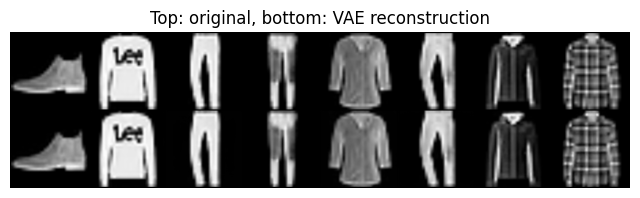

In [5]:
x = torch.stack([test[i][0] for i in range(512)])
mse = sum(F.mse_loss(decode(encode(xb)).cpu(), xb).item() for xb in x.split(128)) / 4
print(f"Reconstruction MSE on 512 test images (pixels in [-1, 1]): {mse:.5f}")
show(torch.cat([x[:8], decode(encode(x[:8])).cpu()]), "Top: original, bottom: VAE reconstruction")

## 2. Forward Diffusion in Latent Space

q(z_t | z_0) = N(z_t; sqrt(ᾱ_t) z_0, (1 − ᾱ_t) I), with T = 1000 and β_t linear from 1e-4 to 0.02. Index 0 is the clean latent (ᾱ_0 = 1).

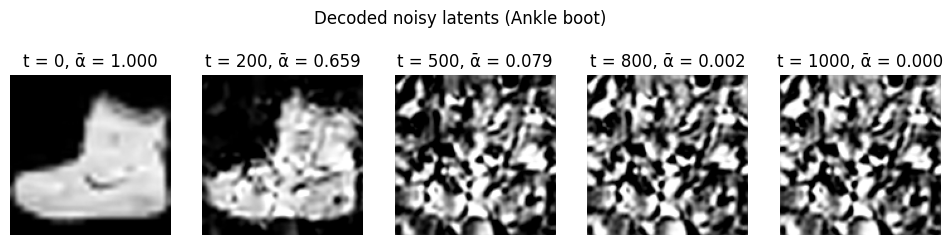

In [6]:
T_STEPS = 1000
betas = torch.cat([torch.zeros(1), torch.linspace(1e-4, 0.02, T_STEPS)]).to(device)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, 0)


def q_sample(z0, t, eps):
    ab = alpha_bar[t].view(-1, 1, 1, 1)
    return ab.sqrt() * z0 + (1 - ab).sqrt() * eps


z0 = z_train[:1].to(device)
eps = torch.randn_like(z0)
ts = [0, 200, 500, 800, 1000]
imgs = [decode(q_sample(z0, torch.tensor([t], device=device), eps))[0, 0].cpu() for t in ts]
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, t, im in zip(axes, ts, imgs):
    ax.imshow(im.clamp(-1, 1) * 0.5 + 0.5, cmap="gray"); ax.set_title(f"t = {t}, ᾱ = {alpha_bar[t].item():.3f}"); ax.axis("off")
plt.suptitle(f"Decoded noisy latents ({CLASSES[y_train[0]]})"); plt.show()

## 3. Conditional UNet with Self Attention

Base channels 64 with multipliers (1, 2, 4), so resolutions 16, 8, 4. Sinusoidal time embedding with an MLP, residual blocks with GroupNorm and SiLU, self attention at 16x16 and in the bottleneck, skip connections. Label embedding has 11 entries (10 classes plus null label 10) and is added to the time embedding.

In [7]:
def timestep_embedding(t, dim):
    half = dim // 2
    f = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    a = t.float()[:, None] * f[None]
    return torch.cat([a.sin(), a.cos()], 1)


class ResBlock(nn.Module):
    def __init__(self, cin, cout, edim):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(edim, cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x))) + self.emb(e)[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)


class Attention(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.norm, self.attn = nn.GroupNorm(8, c), nn.MultiheadAttention(c, 4, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        s = self.norm(x).flatten(2).transpose(1, 2)
        return x + self.attn(s, s, s)[0].transpose(1, 2).reshape(b, c, h, w)


class UNet(nn.Module):
    def __init__(self, cin=4, base=64, mults=(1, 2, 4), n_classes=10):
        super().__init__()
        ch = [base * m for m in mults]  # 64, 128, 256
        e = base * 4
        self.base = base
        self.time_mlp = nn.Sequential(nn.Linear(base, e), nn.SiLU(), nn.Linear(e, e))
        self.label_emb = nn.Embedding(n_classes + 1, e)  # index 10 is the null label
        self.inp = nn.Conv2d(cin, ch[0], 3, padding=1)
        # down: 16x16 -> 8x8 -> 4x4
        self.d1, self.a1 = ResBlock(ch[0], ch[0], e), Attention(ch[0])
        self.down1 = nn.Conv2d(ch[0], ch[0], 3, stride=2, padding=1)
        self.d2 = ResBlock(ch[0], ch[1], e)
        self.down2 = nn.Conv2d(ch[1], ch[1], 3, stride=2, padding=1)
        self.d3 = ResBlock(ch[1], ch[2], e)
        # bottleneck at 4x4
        self.m1, self.ma, self.m2 = ResBlock(ch[2], ch[2], e), Attention(ch[2]), ResBlock(ch[2], ch[2], e)
        # up: 4x4 -> 8x8 -> 16x16
        self.u3 = ResBlock(ch[2] * 2, ch[1], e)
        self.up2 = nn.Upsample(scale_factor=2)
        self.u2 = ResBlock(ch[1] * 2, ch[0], e)
        self.up1 = nn.Upsample(scale_factor=2)
        self.u1, self.ua = ResBlock(ch[0] * 2, ch[0], e), Attention(ch[0])
        self.out = nn.Sequential(nn.GroupNorm(8, ch[0]), nn.SiLU(), nn.Conv2d(ch[0], cin, 3, padding=1))

    def forward(self, x, t, y):
        e = self.time_mlp(timestep_embedding(t, self.base)) + self.label_emb(y)
        h1 = self.a1(self.d1(self.inp(x), e))          # 64 x 16 x 16
        h2 = self.d2(self.down1(h1), e)                # 128 x 8 x 8
        h3 = self.d3(self.down2(h2), e)                # 256 x 4 x 4
        h = self.m2(self.ma(self.m1(h3, e)), e)
        h = self.u3(torch.cat([h, h3], 1), e)          # 128 x 4 x 4
        h = self.u2(torch.cat([self.up2(h), h2], 1), e)  # 64 x 8 x 8
        h = self.ua(self.u1(torch.cat([self.up1(h), h1], 1), e))  # 64 x 16 x 16
        return self.out(h)


model = UNet().to(device)
print(f"U-Net parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

U-Net parameters: 5.60M


## 4. Training

50 epochs, AdamW with LR 2e-5, batch size 128, MSE between true and predicted noise. Labels are replaced by the null label with probability 0.1.

epoch  1 loss 0.4476
epoch  2 loss 0.2063
epoch  3 loss 0.1682
epoch  4 loss 0.1512
epoch  5 loss 0.1392
epoch  6 loss 0.1368
epoch  7 loss 0.1304
epoch  8 loss 0.1261
epoch  9 loss 0.1240
epoch 10 loss 0.1212
epoch 11 loss 0.1201
epoch 12 loss 0.1187
epoch 13 loss 0.1172
epoch 14 loss 0.1164
epoch 15 loss 0.1145
epoch 16 loss 0.1133
epoch 17 loss 0.1134
epoch 18 loss 0.1134
epoch 19 loss 0.1128
epoch 20 loss 0.1109
epoch 21 loss 0.1107
epoch 22 loss 0.1101
epoch 23 loss 0.1080
epoch 24 loss 0.1086
epoch 25 loss 0.1058
epoch 26 loss 0.1071
epoch 27 loss 0.1077
epoch 28 loss 0.1069
epoch 29 loss 0.1064
epoch 30 loss 0.1071
epoch 31 loss 0.1055
epoch 32 loss 0.1051
epoch 33 loss 0.1042
epoch 34 loss 0.1048
epoch 35 loss 0.1036
epoch 36 loss 0.1049
epoch 37 loss 0.1045
epoch 38 loss 0.1036
epoch 39 loss 0.1036
epoch 40 loss 0.1027
epoch 41 loss 0.1026
epoch 42 loss 0.1020
epoch 43 loss 0.1020
epoch 44 loss 0.1018
epoch 45 loss 0.1008
epoch 46 loss 0.1003
epoch 47 loss 0.1026
epoch 48 loss

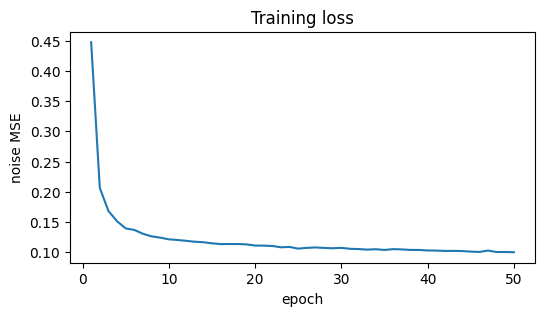

In [8]:
EPOCHS, LR, BS, P_DROP, NULL = 50, 2e-5, 128, 0.1, 10
opt = torch.optim.AdamW(model.parameters(), lr=LR)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(z_train, y_train), batch_size=BS, shuffle=True, drop_last=True)
losses = []
model.train()
for epoch in range(EPOCHS):
    total = 0
    for z0, y in loader:
        z0, y = z0.to(device), y.to(device)
        y = torch.where(torch.rand(len(y), device=device) < P_DROP, torch.full_like(y, NULL), y)
        t = torch.randint(1, T_STEPS + 1, (len(z0),), device=device)
        eps = torch.randn_like(z0)
        loss = F.mse_loss(model(q_sample(z0, t, eps), t, y), eps)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item()
    losses.append(total / len(loader))
    print(f"epoch {epoch + 1:2d} loss {losses[-1]:.4f}")
torch.save(model.state_dict(), "ldm_unet.pt")

plt.figure(figsize=(6, 3)); plt.plot(range(1, EPOCHS + 1), losses); plt.xlabel("epoch"); plt.ylabel("noise MSE"); plt.title("Training loss"); plt.show()

## 5. Sampling with Classifier Free Guidance

DDPM ancestral sampling over all 1000 steps. Each step runs the model with the class label and with the null label, then combines them as ε = (1 + w) ε_cond − w ε_uncond with w = 3. Labels are 0 to 9 repeated for 64 images.

labels: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


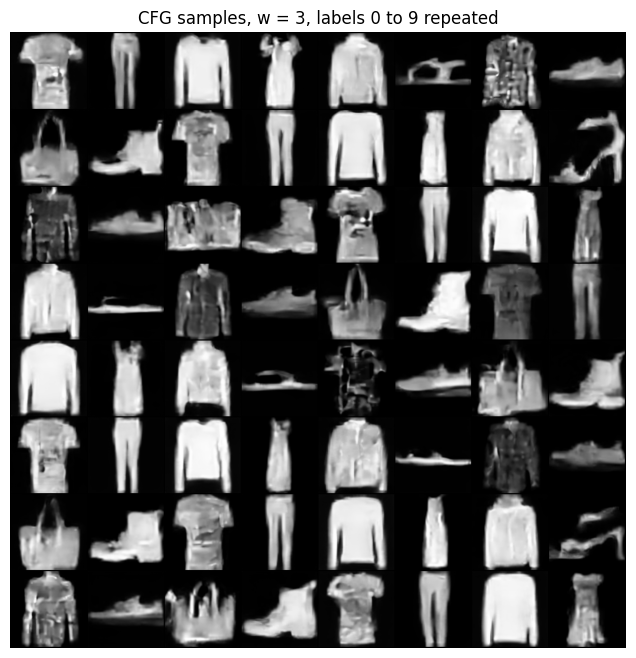

In [9]:
@torch.no_grad()
def sample(y, w=3.0):
    model.eval()
    n = len(y)
    z = torch.randn(n, 4, 16, 16, device=device)
    y_both = torch.cat([y, torch.full_like(y, NULL)])
    for t in range(T_STEPS, 0, -1):
        tt = torch.full((2 * n,), t, device=device)
        e_cond, e_uncond = model(torch.cat([z, z]), tt, y_both).chunk(2)
        eps = (1 + w) * e_cond - w * e_uncond
        z = (z - betas[t] / (1 - alpha_bar[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 1:
            z = z + betas[t].sqrt() * torch.randn_like(z)
    return z


torch.manual_seed(SEED)
labels = torch.arange(64, device=device) % 10
imgs = torch.cat([decode(zb) for zb in sample(labels).split(16)])
print("labels:", [CLASSES[i] for i in labels[:10].tolist()])
show(imgs, "CFG samples, w = 3, labels 0 to 9 repeated")

## Analysis

**VAE.** Each 128x128 image becomes a 4x16x16 latent, 48 times fewer values than the 3x128x128 input. Reconstruction MSE is 0.00077 on 512 test images, and the reconstructions keep fine details such as text and plaid patterns, so the latent space is a good place to run diffusion.

**Forward diffusion.** At t = 200 the item is still visible. By t = 500 (ᾱ = 0.079) the shape is gone, and at t = 800 and t = 1000 the decoded latent is pure noise. Noise in latent space decodes to blotchy textures, not pixel noise, because the decoder turns every latent into image like structure.

**Training.** Noise prediction loss falls from about 0.14 at epoch 6 to 0.0998 at epoch 50 and is still slowly going down, so the small learning rate of 2e-5 means the model could train longer.

**Sampling.** With guidance scale w = 3, each of the 64 samples matches its label by eye: trousers, sandals, sneakers, bags and ankle boots are clean and clearly separated. The tops (T shirt, pullover, coat, shirt) look alike and some shirts and coats have noisy textures, which matches the classes that FashionMNIST classifiers also confuse most. Guidance pushes the prediction away from the unconditional one, so samples follow the class strongly but show less variety within a class.